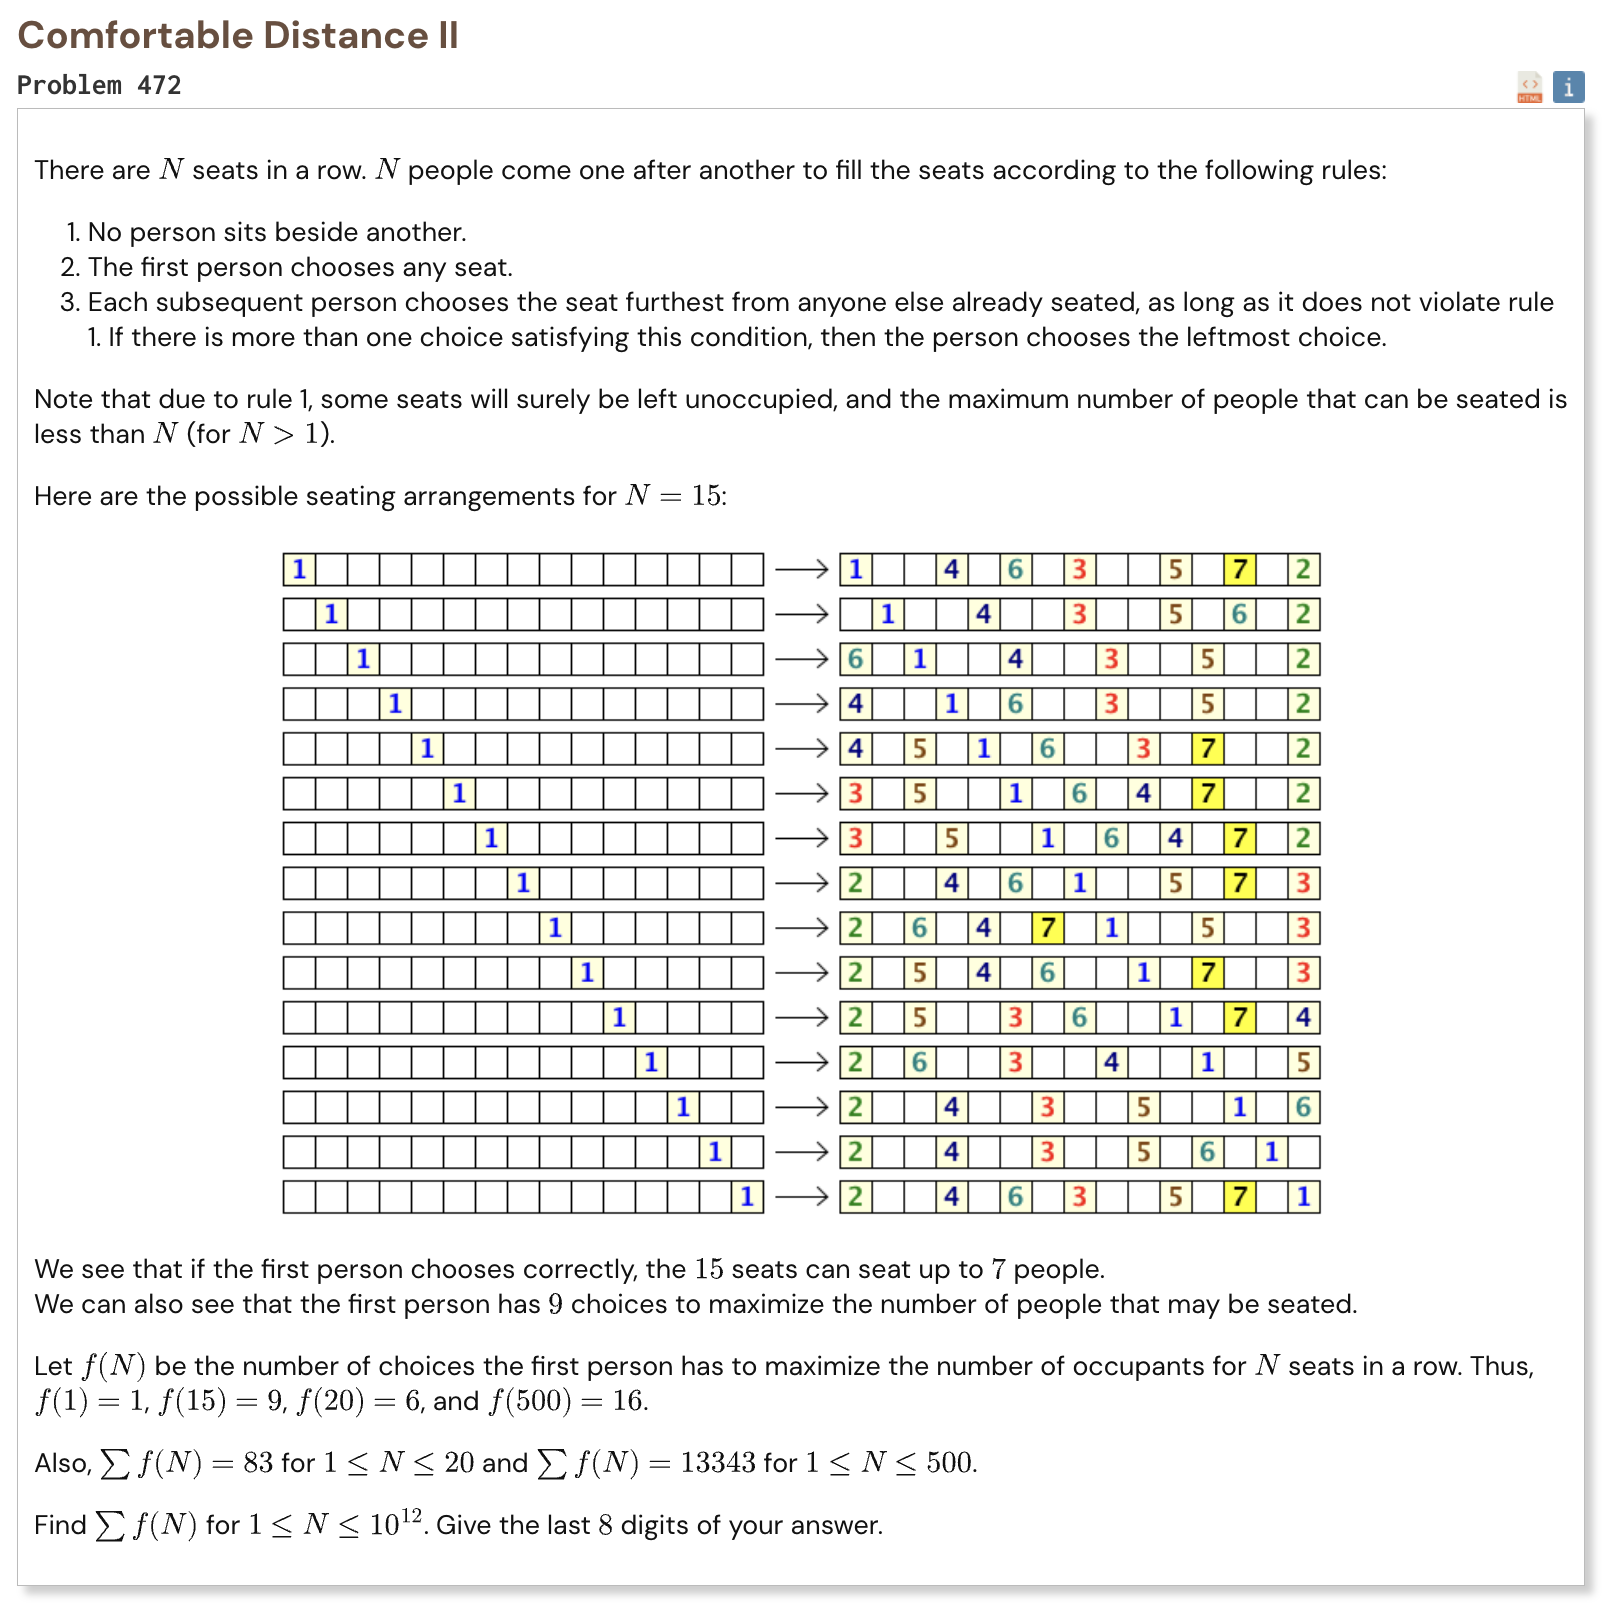

## Initial approach

- the values of f(N) form repeating self-similar blocks between consecutive powers of two
- store the first few small blocks directly because they reveal the pattern
- every larger block starts by copying part of the previous block
- the rest of the block consists of three simple arithmetic sequences
- derive closed formulas for the prefix sum of each of those three pieces
- use recursion only when the requested prefix falls inside the copied part
- this reduces a sum up to one trillion seats to only about forty block levels
- calculate the full prefix sum and keep only the last eight digits

In [1]:
%%time

N = 10**12
MOD = 100_000_000

seed_blocks = [
    [2],
    [2, 4],
    [3, 6, 2, 6],
    [3, 8, 2, 6, 2, 4, 9, 4],
    [3, 8, 2, 6, 2, 4, 10, 4, 2, 4, 6, 8, 15, 6, 5, 4]
]

max_k = N.bit_length()

base_prefix = []
block_sum = []

for block in seed_blocks:
    prefix = [0]
    total = 0

    for value in block:
        total += value
        prefix.append(total)

    base_prefix.append(prefix)
    block_sum.append(total)

quarter_sum = [0] * (max_k + 1)

for k in range(2, 5):
    length = 3 * (1 << (k - 2))
    quarter_sum[k] = base_prefix[k][length]

for k in range(5, max_k + 1):
    r = 1 << (k - 3)

    part_a = r * (r + 5)
    part_b = 4 * r * r + 2 * r
    part_c = 2 * r * r + 11 * r

    quarter_sum[k] = quarter_sum[k - 1] + part_a + part_b
    block_sum.append(quarter_sum[k] + part_c)

power_prefix = [0] * (max_k + 2)
power_prefix[0] = 1

for k in range(max_k + 1):
    power_prefix[k + 1] = power_prefix[k] + block_sum[k]

def prefix_a(r, m):
    if m == 0:
        return 0

    return (
        4 * r
        + 2
        + (m - 1) * (2 * r - m + 2)
    )

def sum_a(r):
    return r * (r + 5)

def prefix_b(m):
    return m * (m + 1)

def sum_b(r):
    return 4 * r * r + 2 * r

def prefix_c(r, m):
    if m == 0:
        return 0

    return (
        6 * r
        + 3
        + (m - 1) * (4 * r - m + 6) // 2
    )

def block_prefix(k, m):
    if m <= 0:
        return 0

    length = 1 << k

    if m >= length:
        return block_sum[k]

    if k <= 4:
        return base_prefix[k][m]

    r = 1 << (k - 3)
    first = 3 * r
    second = r
    third = 2 * r

    if m <= first:
        return block_prefix(k - 1, m)

    if m <= first + second:
        return (
            quarter_sum[k - 1]
            + prefix_a(r, m - first)
        )

    if m <= first + second + third:
        return (
            quarter_sum[k - 1]
            + sum_a(r)
            + prefix_b(m - first - second)
        )

    return (
        quarter_sum[k - 1]
        + sum_a(r)
        + sum_b(r)
        + prefix_c(
            r,
            m - first - second - third
        )
    )

def prefix_sum(n):
    if n == 0:
        return 0

    if n == 1:
        return 1

    k = n.bit_length() - 1
    power = 1 << k

    total = power_prefix[k]

    if n > power:
        total += block_prefix(
            k,
            n - power
        )

    return total

result = prefix_sum(N) % MOD

print("Result:", f"{result:08d}")

Result: 73811586
CPU times: user 235 μs, sys: 39 μs, total: 274 μs
Wall time: 271 μs
